# Initialisation

In [ ]:
# initialisation packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import scipy.stats as stats
from matplotlib.patches import Patch

import pymrio

# initialisation Exiobase 2021
path_2021 = r"C:\path_to_your_directory\IOT_2021_pxp.zip"  # Replace with the actual path to your zip file Exiobase 2021"
exio_data_2021 = pymrio.parse_exiobase3(path=path_2021)

# initialisation variables 2021
exio_data_2021.calc_all(include_ghosh=True)

Z = exio_data_2021.Z
x = exio_data_2021.x.squeeze()
Y = exio_data_2021.Y
A = exio_data_2021.A
L = exio_data_2021.L.squeeze()
G = exio_data_2021.G
B = exio_data_2021.B

F = exio_data_2021.satellite.F
I = exio_data_2021.impacts.F.squeeze()
S = exio_data_2021.impacts.S

Z1 = Z.sum(axis=1) # total des ventes par secteur
Z0 = Z.sum(axis=0) # total des achats par secteur
Y_total = Y.sum(axis=1)
J = S.loc[('GHG emissions AR5 (GWP100) | GWP100 (IPCC, 2010)')].T
v = I.loc[('Value Added')].T
v_coeff = S.loc[('Value Added')].T

# initialisation catégories secteurs
data_regions = pd.read_excel(r"C:\path_to_your_directory\caractéristique régions.xlsx", header=0, index_col=0) # Replace with the actual path to the file"
data_sectors = pd.read_excel(r"C:\path_to_your_directory\caractéristique secteurs.xlsx", header=0, index_col=0) # Replace with the actual path to the file"

# fonctions et index_4

def safe_divide(numerator, denominator):
    """Divise deux valeurs, retourne nan si dénominateur est 0 ou NaN"""
    if denominator == 0:
        return np.nan
    return numerator / denominator

index_agg = list(x.index)
for i in range(len(list(x.index))):
    index_agg[i] = (list(x.index)[i][0], list(x.index)[i][1], data_regions.loc[list(x.index)[i][0], 'Aggregated Regions'], data_sectors.loc[list(x.index)[i][1], 'Aggregated Sectors'])

columns_index = ['regions','sectors','aggregated_regions','aggregated_sectors']
index_4 = pd.MultiIndex.from_tuples(index_agg, names=columns_index)

x_4 = x.copy()
x_4.index = index_4

Y_total_4 = Y_total.copy()
Y_total_4.index = index_4

v_4 = v.copy()
v_4.index = index_4

CC_GES = 29.9e12 # Capacité de charge globale GES (2°C) en kg CO2-eq/an (source: Chandramukar et al., 2018) https://doi.org/10.1111/jiec.12830

In [ ]:
# initialisation 1995

path_1995 = r"C:\path_to_your_directory\IOT_1995_pxp.zip" # Replace with the actual path to your zip file Exiobase 1995"
exio_data_1995 = pymrio.parse_exiobase3(path=path_1995)

exio_data_1995.calc_all(include_ghosh=True)
Z_1995 = exio_data_1995.Z
x_1995 = exio_data_1995.x.squeeze()
Y_1995 = exio_data_1995.Y
A_1995 = exio_data_1995.A
L_1995 = exio_data_1995.L.squeeze()
G_1995 = exio_data_1995.G
B_1995 = exio_data_1995.B

F_1995 = exio_data_1995.satellite.F
I_1995 = exio_data_1995.impacts.F.squeeze()
S_1995 = exio_data_1995.impacts.S

Z1_1995 = Z_1995.sum(axis=1) # total des ventes par secteur
Z0_1995 = Z_1995.sum(axis=0) # total des achats par secteur
Y_total_1995 = Y_1995.sum(axis=1)
J_1995 = S_1995.loc[('GHG emissions AR5 (GWP100) | GWP100 (IPCC, 2010)')].T
v_1995 = I_1995.loc[('Value Added')].T
v_coeff_1995 = S_1995.loc[('Value Added')].T

# Impact calculation

In [ ]:
# calculation (2021)

# Calcul PBA
I_direct = J * x
I_direct.index = index_4
I_agg_direct = I_direct.groupby(level=[2,3]).sum()
print(I_direct.sum())

# calcul CBA
Y_eye = pd.DataFrame(np.diag(Y_total), index=Y_total.index, columns=Y_total.index)
X_amont_eye = L @ Y_eye
I_amont = J.T @ X_amont_eye
I_amont.index = index_4
I_agg_amont = I_amont.groupby(level=[2,3]).sum()
print(I_amont.sum())

# calcul IBA
V_eye = pd.DataFrame(np.diag(v), index=v.index, columns=v.index)
X_aval_eye = (V_eye @ G).T
I_aval = J.T @ X_aval_eye
I_aval.index = index_4
I_agg_aval = I_aval.groupby(level=[2,3]).sum()
print(I_aval.sum())

# Attributed climate change impacts
AI = pd.DataFrame({'PBA': I_direct, 'CBA': I_amont, 'IBA': I_aval})

# AI.to_excel("Attributed_Impacts.xlsx", index=False)

49074672204150.67
49074672204137.375
49074672841701.34


In [5]:
# calculation (1995)

# Calcul PBA
I_direct_1995 = J_1995 * x_1995
I_direct_1995.index = index_4
I_agg_direct_1995 = I_direct_1995.groupby(level=[2,3]).sum()
print(I_direct_1995.sum())

# calcul CBA
Y_eye_1995 = pd.DataFrame(np.diag(Y_total_1995), index=Y_total_1995.index, columns=Y_total_1995.index)
X_amont_eye_1995 = L_1995 @ Y_eye_1995
I_amont_1995 = J_1995.T @ X_amont_eye_1995
I_amont_1995.index = index_4
I_agg_amont_1995 = I_amont_1995.groupby(level=[2,3]).sum()
print(I_amont_1995.sum())

# calcul IBA
V_eye_1995 = pd.DataFrame(np.diag(v_1995), index=v_1995.index, columns=v_1995.index)
X_aval_eye_1995 = (V_eye_1995 @ G_1995).T
I_aval_1995 = J_1995.T @ X_aval_eye_1995
I_aval_1995.index = index_4
I_agg_aval_1995 = I_aval_1995.groupby(level=[2,3]).sum()
print(I_aval_1995.sum())

26980345854445.96
26980345854448.234
26980346391112.36


# aCC and ESR calculations

In [ ]:
# aCC et ESR sans aggrégation

# aCC "utilitarism"
columns_util = ['aCC_PBA_GO','aCC_CBA_FCE','aCC_IBA_GVA']
aCC_util = pd.DataFrame(np.zeros((x.shape[0], len(columns_util))), index=index_4, columns=columns_util)
for index in aCC_util.index:
    aCC_util.loc[index, 'aCC_PBA_GO'] = CC_GES * x.loc[index[:2]] / x.sum()
    aCC_util.loc[index, 'aCC_CBA_FCE'] = CC_GES * Y_total.loc[index[:2]] / Y_total.sum()
    aCC_util.loc[index, 'aCC_IBA_GVA'] = CC_GES * (v.loc[index[:2]] / v.sum())
# aCC "grandfathering"
columns_GF = ['aCC_PBA_GF','aCC_CBA_GF','aCC_IBA_GF']
aCC_GF = pd.DataFrame(np.zeros((x.shape[0], len(columns_GF))), index=index_4, columns=columns_GF)

for index in index_4:
    aCC_GF.loc[index, 'aCC_PBA_GF'] = CC_GES * I_direct_1995.loc[index] / I_direct_1995.sum()
    aCC_GF.loc[index, 'aCC_CBA_GF'] = CC_GES * I_amont_1995.loc[index] / I_amont_1995.sum()
    aCC_GF.loc[index, 'aCC_IBA_GF'] = CC_GES * I_aval_1995.loc[index] / I_aval_1995.sum()

aCC = pd.DataFrame({'GO': aCC_util['aCC_PBA_GO'], 'FCE': aCC_util['aCC_CBA_FCE'], 'GVA': aCC_util['aCC_IBA_GVA'], 'GF (PBA, 1995)': aCC_GF['aCC_PBA_GF'], 'GF (CBA, 1995)': aCC_GF['aCC_CBA_GF'], 'GF (IBA, 1995)': aCC_GF['aCC_IBA_GF']})
# aCC.to_excel("Allocated_Carrying_Capacities.xlsx", index=False)

# ESR "utilitarianism"
ESR_util = aCC_util.copy()
ESR_util.columns = ['ESR_PBA_GO', 'ESR_CBA_FCE', 'ESR_IBA_GVA']

for i in ESR_util.index:
    ESR_util.loc[i].loc['ESR_PBA_GO'] = safe_divide(I_direct.loc[i], aCC_util.loc[i].loc['aCC_PBA_GO'])
    ESR_util.loc[i].loc['ESR_CBA_FCE'] = safe_divide(I_amont.loc[i], aCC_util.loc[i].loc['aCC_CBA_FCE'])
    ESR_util.loc[i].loc['ESR_IBA_GVA'] = safe_divide(I_aval.loc[i], aCC_util.loc[i].loc['aCC_IBA_GVA'])

# ESR "grandfathering"
ESR_GF = aCC_GF.copy()
ESR_GF.columns = ['ESR_PBA_GF', 'ESR_CBA_GF', 'ESR_IBA_GF']

for i in ESR_GF.index:
    ESR_GF.loc[i].loc['ESR_PBA_GF'] = safe_divide(I_direct.loc[i], aCC_GF.loc[i].loc['aCC_PBA_GF'])
    ESR_GF.loc[i].loc['ESR_CBA_GF'] = safe_divide(I_amont.loc[i], aCC_GF.loc[i].loc['aCC_CBA_GF'])
    ESR_GF.loc[i].loc['ESR_IBA_GF'] = safe_divide(I_aval.loc[i], aCC_GF.loc[i].loc['aCC_IBA_GF'])

C:\Users\gguillemaud\AppData\Local\Temp\ipykernel_9924\1307305008.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  aCC_util.loc[index, 'aCC_PBA_GO'] = CC_GES * x.loc[index[:2]] / x.sum()
C:\Users\gguillemaud\AppData\Local\Temp\ipykernel_9924\1307305008.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  aCC_util.loc[index, 'aCC_CBA_FCE'] = CC_GES * Y_total.loc[index[:2]] / Y_total.sum()
C:\Users\gguillemaud\AppData\Local\Temp\ipykernel_9924\1307305008.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  aCC_util.loc[index, 'aCC_IBA_GVA'] = CC_GES * (v.loc[index[:2]] / v.sum())
C:\Users\gguillemaud\AppData\Local\Temp\ipykernel_9924\1307305008.py:15: PerformanceWarning: indexing past lexsort depth may impact performance.
  aCC_GF.loc[index, 'aCC_PBA_GF'] = CC_GES * I_direct_1995.loc[index] / I_direct_1995.sum()
C:\Users\gguillemaud\AppData\Local\Temp\ipykernel_9924\1307305008.py:16: PerformanceWarning: 

# Plot

C:\Users\gguillemaud\AppData\Local\Temp\ipykernel_9924\910364118.py:47: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  return [plt.cm.get_cmap(cmap_name)(w) for w in vals]


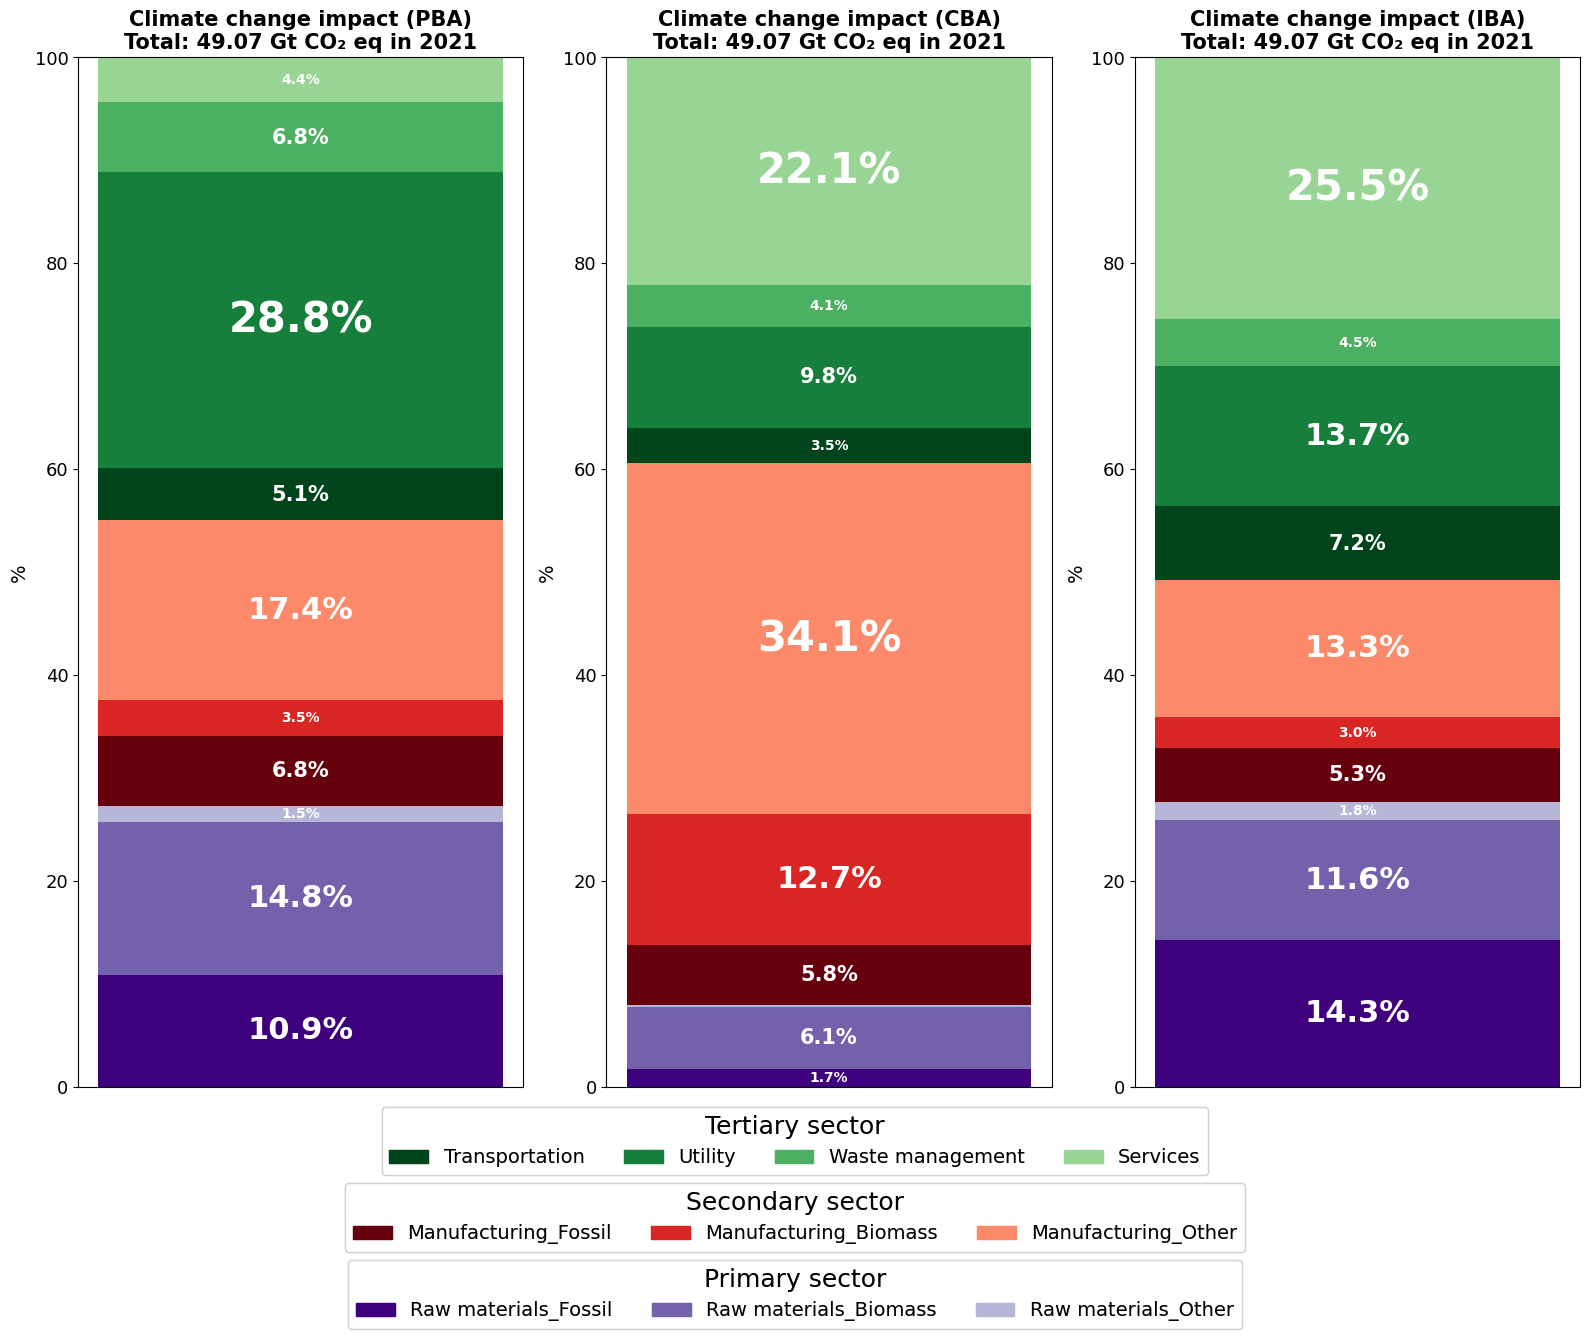

In [7]:
# Stackbar GHG emissions (fig 3)

# Regrouper les impacts (I_direct, I_amont, I_aval) par secteur agrégé
I_direct_by_sector = I_agg_direct.groupby(level=1).sum() / 1e12
I_amont_by_sector = I_agg_amont.groupby(level=1).sum() / 1e12
I_aval_by_sector = I_agg_aval.groupby(level=1).sum() / 1e12

# Créer les données pour stackbar
data_stackbar = pd.DataFrame({
    'PBA': I_direct_by_sector,
    'CBA': I_amont_by_sector,
    'IBA': I_aval_by_sector
})

# Ordre de référence unique des secteurs
sector_order = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other',
                'Manufacturing_Fossil',
                'Manufacturing_Biomass',
                'Manufacturing_Other',
                'Transportation',
                'Utility',
                'Waste management',
                'Services'
                ]

# Regrouper les secteurs en 3 familles
primary_sectors = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other']
secondary_sectors = ['Manufacturing_Fossil',
                        'Manufacturing_Biomass',
                        'Manufacturing_Other']
tertiary_sectors = ['Transportation',
                'Utility',
                'Waste management',
                'Services']

# Dégradés de couleurs par famille (plus contrastés)
def gradient_colors(cmap_name, n, vmin=1, vmax=0.4):
    if n == 0:
        return []
    if n == 1:
        return [plt.cm.get_cmap(cmap_name)(0.8)]
    vals = np.linspace(vmin, vmax, n)
    return [plt.cm.get_cmap(cmap_name)(w) for w in vals]

sector_colors = {}
for s, c in zip(primary_sectors, gradient_colors('Purples', len(primary_sectors))):
    sector_colors[s] = c
for s, c in zip(secondary_sectors, gradient_colors('Reds', len(secondary_sectors))):
    sector_colors[s] = c
for s, c in zip(tertiary_sectors, gradient_colors('Greens', len(tertiary_sectors))):
    sector_colors[s] = c

# Créer 3 barplots empilés (1 par accounting approach)
fig, axes = plt.subplots(1, 3, figsize=(16, 14))

acc_approach = ['PBA', 'CBA', 'IBA']
data_fig3 = pd.DataFrame(np.zeros((len(sector_order), len(acc_approach))), index=sector_order, columns=acc_approach)

for idx, acc_appr in enumerate(acc_approach):
    ax = axes[idx]
    # Ordre fixe identique pour les 3 accounting approaches
    data_acc = data_stackbar[acc_appr].reindex(sector_order)
    total_acc = data_acc.sum()
    data_acc_pct = (data_acc / total_acc * 100) if total_acc != 0 else data_acc * 0

    data_fig3.iloc[:, idx] = data_acc_pct
    
    # Ajouter les segments empilés avec la couleur fixe pour chaque secteur
    bottom = 0
    for sector, value_pct in data_acc_pct.items():
        ax.bar(0, value_pct, bottom=bottom, width=0.5, label=sector, color=sector_colors[sector])
        # Ajouter le label de la valeur
        if value_pct > 1:
            if value_pct > 20:
                ft = 30
            elif value_pct > 10:
                ft = 22
            elif value_pct > 5:
                ft = 15
            else:
                ft = 10
            ax.text(0, bottom + value_pct/2, f'{value_pct:.1f}%', ha='center', va='center', fontsize=ft, fontweight='bold', color='white')
        bottom += value_pct
    
    ax.set_title(f'Climate change impact ({acc_appr})\nTotal: {total_acc:.2f} Gt CO₂ eq in 2021', fontsize=15, fontweight='bold')
    ax.set_ylabel('%', fontsize=14)
    ax.set_ylim(0, 100)
    ax.set_xticks([])
    #ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='y', labelsize=13)

# 3 sous-légendes distinctes

handles_tertiary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in tertiary_sectors]
leg3 = fig.legend(handles_tertiary, tertiary_sectors, loc='lower center',
                  ncol=min(4, len(tertiary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.15), frameon=True,
                  title='Tertiary sector', title_fontsize=18)
fig.add_artist(leg3)

handles_secondary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in secondary_sectors]
leg2 = fig.legend(handles_secondary, secondary_sectors, loc='lower center',
                  ncol=min(4, len(secondary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.095), frameon=True,
                  title='Secondary sector', title_fontsize=18)
fig.add_artist(leg2)

handles_primary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in primary_sectors]
leg1 = fig.legend(handles_primary, primary_sectors, loc='lower center',
                  ncol=min(4, len(primary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.04), frameon=True,
                  title='Primary sector', title_fontsize=18)
fig.add_artist(leg1)

plt.tight_layout()
plt.subplots_adjust(bottom=0.22)
plt.show()

C:\Users\gguillemaud\AppData\Local\Temp\ipykernel_9924\3346269105.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  return [plt.cm.get_cmap(cmap_name)(w) for w in vals]


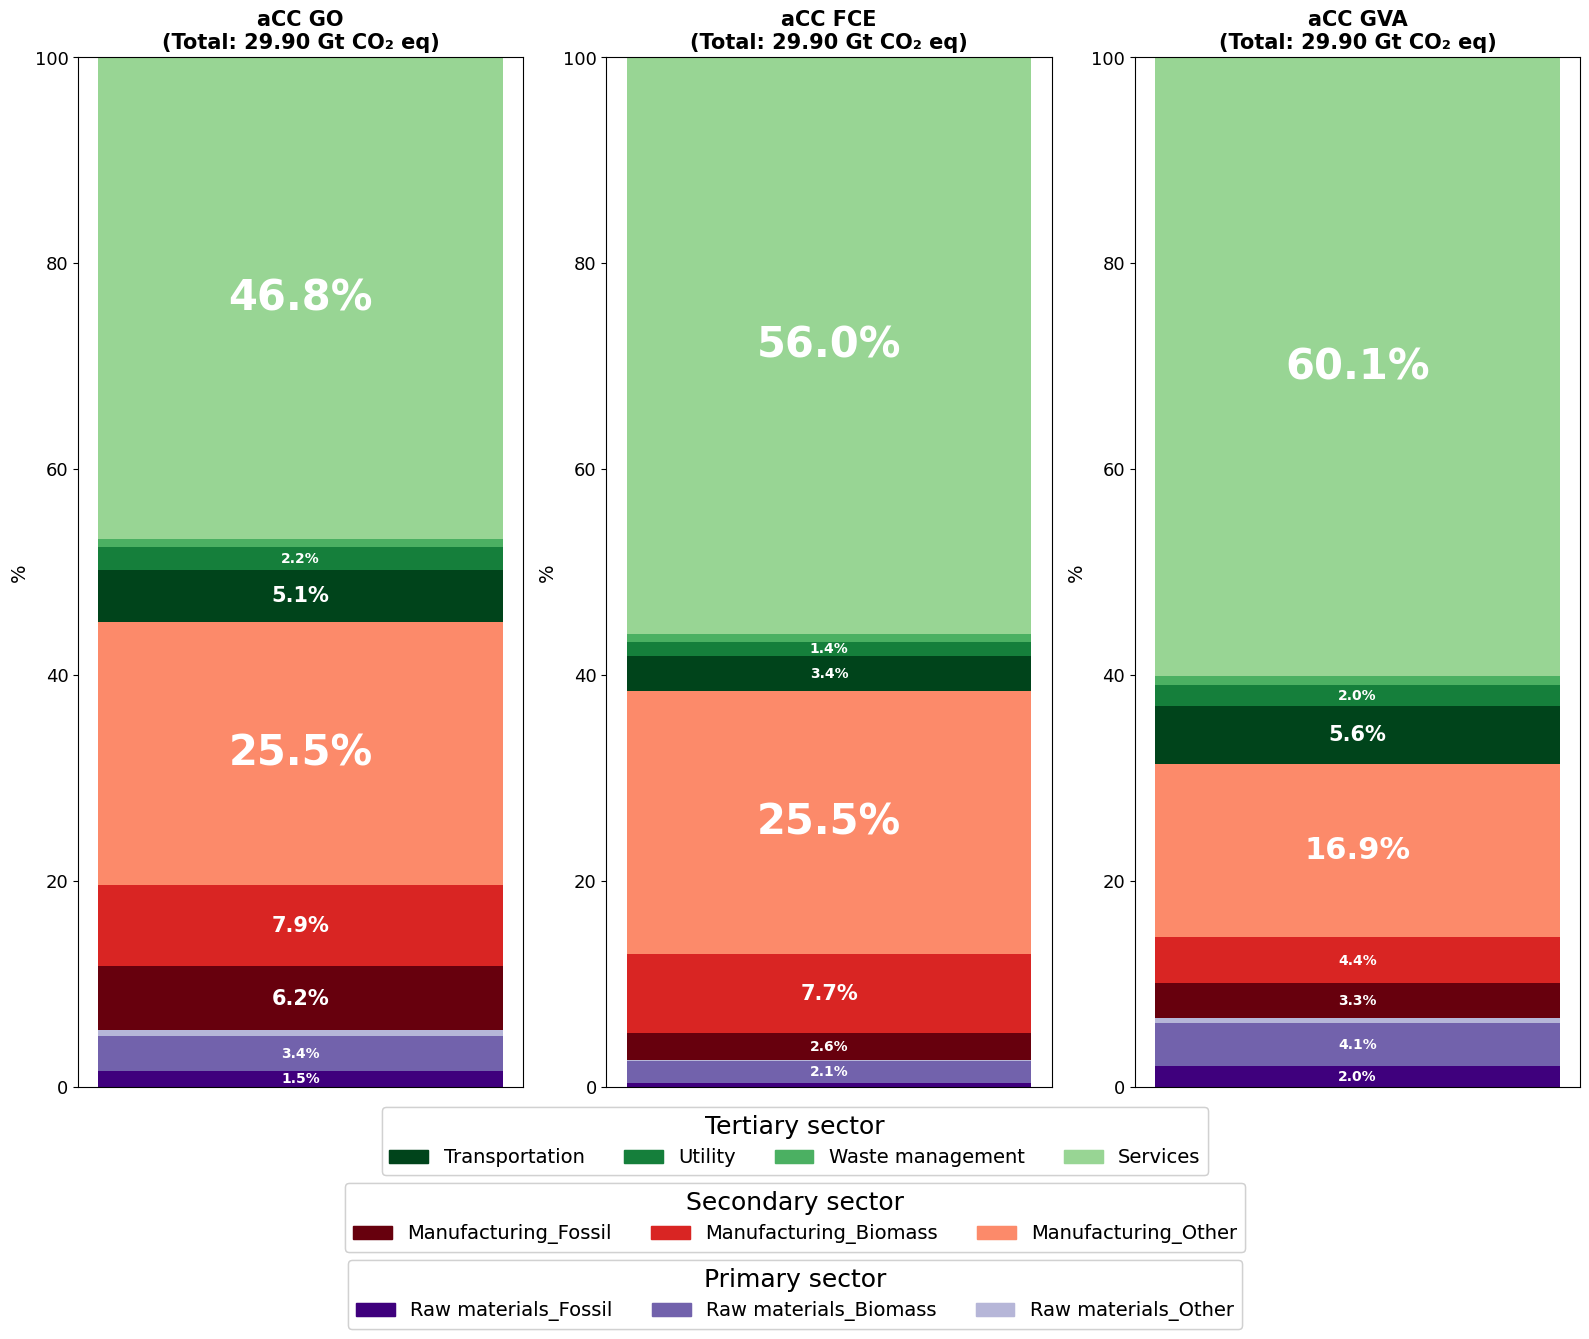

In [ ]:
# Stackbar aCC utilitarianism (fig 4a)

columns = ['aCC GO', 'aCC FCE', 'aCC GVA']

# Créer les données pour stackbar
data_stackbar = aCC_util.groupby(level=[3]).sum() / 1e12
data_stackbar.columns = columns


# Ordre de référence unique des secteurs
sector_order = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other',
                'Manufacturing_Fossil',
                'Manufacturing_Biomass',
                'Manufacturing_Other',
                'Transportation',
                'Utility',
                'Waste management',
                'Services'
                ]

# Regrouper les secteurs en 3 familles
primary_sectors = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other']
secondary_sectors = ['Manufacturing_Fossil',
                        'Manufacturing_Biomass',
                        'Manufacturing_Other']
tertiary_sectors = ['Transportation',
                'Utility',
                'Waste management',
                'Services']

# Dégradés de couleurs par famille
def gradient_colors(cmap_name, n, vmin=1, vmax=0.4):
    if n == 0:
        return []
    if n == 1:
        return [plt.cm.get_cmap(cmap_name)(0.8)]
    vals = np.linspace(vmin, vmax, n)
    return [plt.cm.get_cmap(cmap_name)(w) for w in vals]

sector_colors = {}
for s, c in zip(primary_sectors, gradient_colors('Purples', len(primary_sectors))):
    sector_colors[s] = c
for s, c in zip(secondary_sectors, gradient_colors('Reds', len(secondary_sectors))):
    sector_colors[s] = c
for s, c in zip(tertiary_sectors, gradient_colors('Greens', len(tertiary_sectors))):
    sector_colors[s] = c

# Créer 3 barplots empilés (1 par accounting approach)
fig, axes = plt.subplots(1, 3, figsize=(16, 14))

data_fig4a = pd.DataFrame(np.zeros((len(sector_order), len(columns))), index=sector_order, columns=columns)

for idx, acc_appr in enumerate(columns):
    ax = axes[idx]
    # Ordre fixe identique pour les 3 accounting approaches
    data_acc = data_stackbar[acc_appr].reindex(sector_order)
    total_acc = data_acc.sum()
    data_acc_pct = (data_acc / total_acc * 100) if total_acc != 0 else data_acc * 0

    data_fig4a.iloc[:, idx] = data_acc_pct
    
    # Ajouter les segments empilés avec la couleur fixe pour chaque secteur
    bottom = 0
    for sector, value_pct in data_acc_pct.items():
        ax.bar(0, value_pct, bottom=bottom, width=0.5, label=sector, color=sector_colors[sector])
        # Ajouter le label de la valeur
        if value_pct > 1:
            if value_pct > 20:
                ft = 30
            elif value_pct > 10:
                ft = 22
            elif value_pct > 5:
                ft = 15
            else:
                ft = 10
            ax.text(0, bottom + value_pct/2, f'{value_pct:.1f}%', ha='center', va='center', fontsize=ft, fontweight='bold', color='white')
        bottom += value_pct
    
    ax.set_title(f'{acc_appr}\n(Total: {total_acc:.2f} Gt CO₂ eq)', fontsize=15, fontweight='bold')
    ax.set_ylabel('%', fontsize=14)
    ax.set_ylim(0, 100)
    ax.set_xticks([])
    #ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='y', labelsize=13)

# 3 sous-légendes distinctes

handles_tertiary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in tertiary_sectors]
leg3 = fig.legend(handles_tertiary, tertiary_sectors, loc='lower center',
                  ncol=min(4, len(tertiary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.15), frameon=True,
                  title='Tertiary sector', title_fontsize=18)
fig.add_artist(leg3)

handles_secondary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in secondary_sectors]
leg2 = fig.legend(handles_secondary, secondary_sectors, loc='lower center',
                  ncol=min(4, len(secondary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.095), frameon=True,
                  title='Secondary sector', title_fontsize=18)
fig.add_artist(leg2)

handles_primary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in primary_sectors]
leg1 = fig.legend(handles_primary, primary_sectors, loc='lower center',
                  ncol=min(4, len(primary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.04), frameon=True,
                  title='Primary sector', title_fontsize=18)
fig.add_artist(leg1)

plt.tight_layout()
plt.subplots_adjust(bottom=0.22)
plt.show()

C:\Users\gguillemaud\AppData\Local\Temp\ipykernel_9924\198302912.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  return [plt.cm.get_cmap(cmap_name)(w) for w in vals]


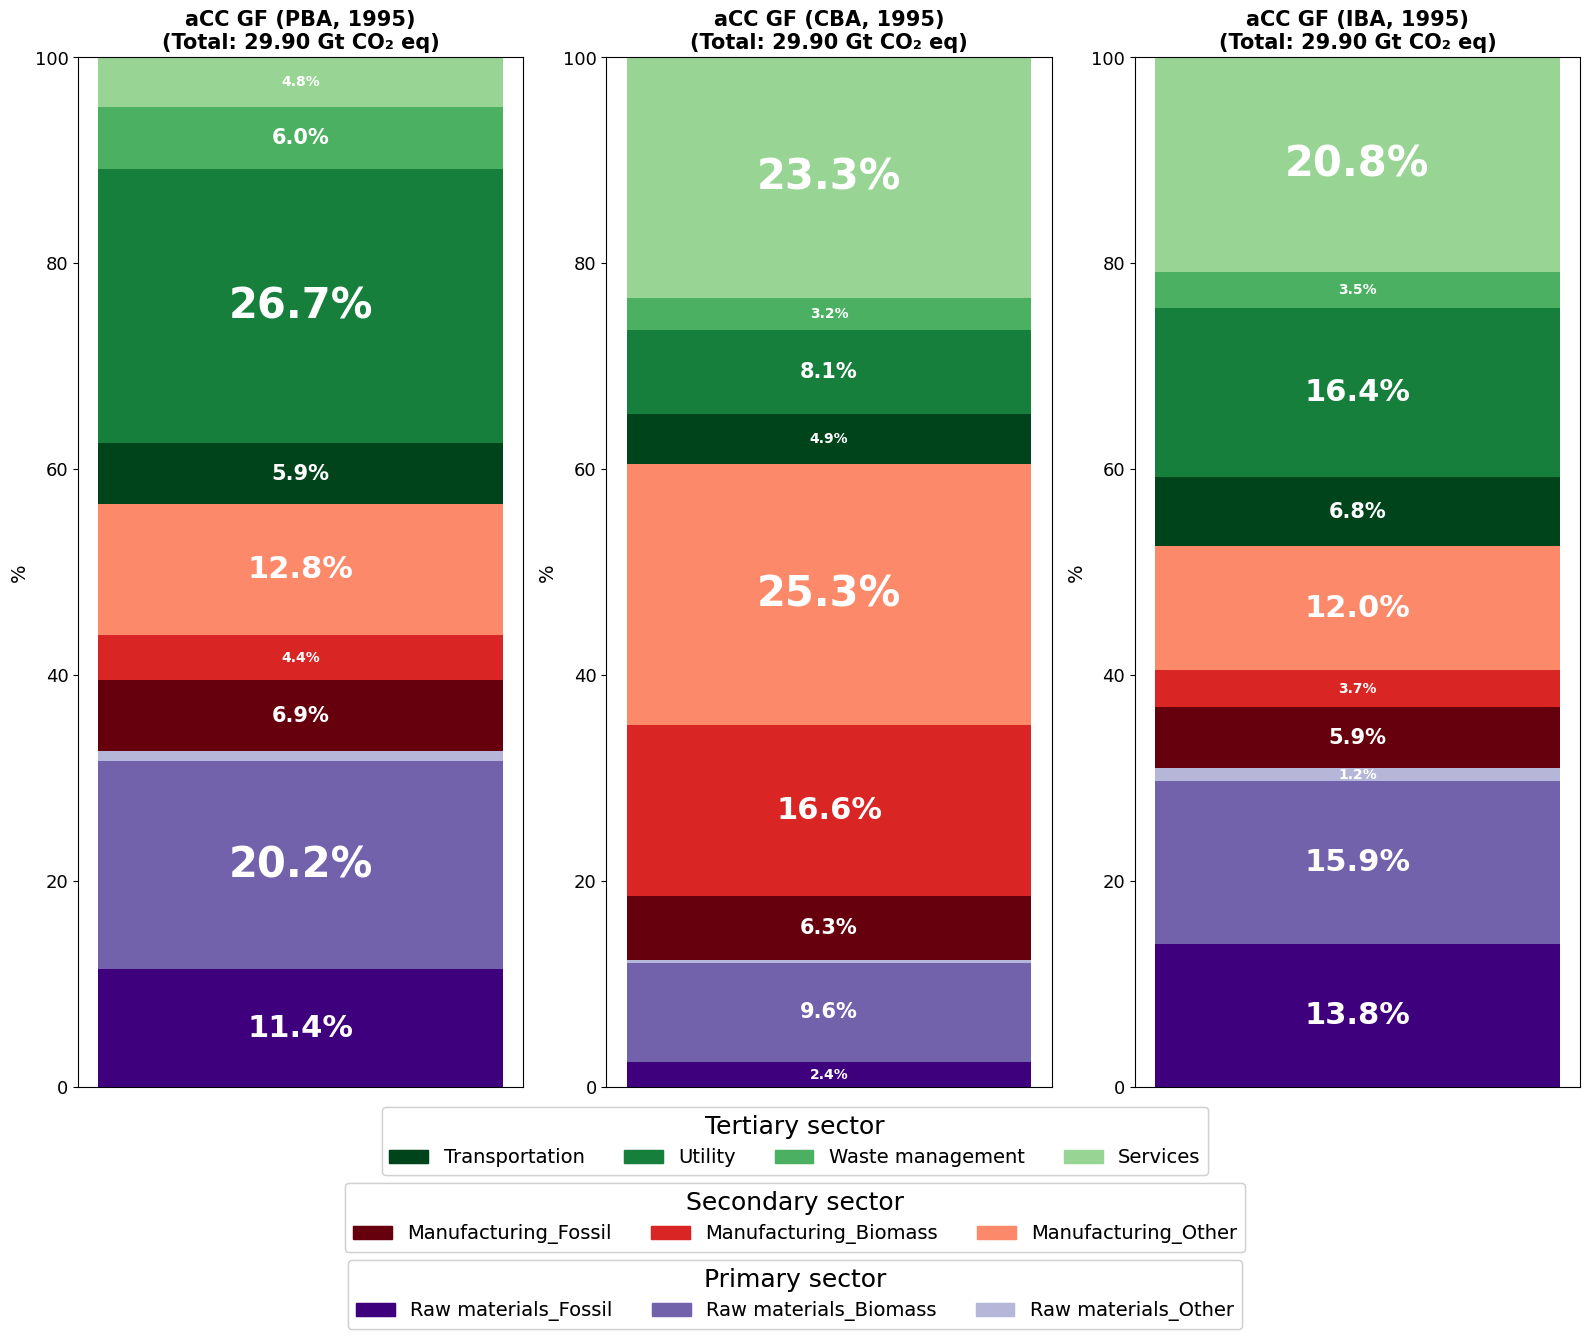

In [10]:
# Stackbar aCC grandfathering (fig 4b)

columns = ['aCC GF (PBA, 1995)', 'aCC GF (CBA, 1995)', 'aCC GF (IBA, 1995)']

# Créer les données pour stackbar
data_stackbar = aCC_GF.groupby(level=[3]).sum() / 1e12
data_stackbar.columns = columns


# Ordre de référence unique des secteurs
sector_order = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other',
                'Manufacturing_Fossil',
                'Manufacturing_Biomass',
                'Manufacturing_Other',
                'Transportation',
                'Utility',
                'Waste management',
                'Services'
                ]

# Regrouper les secteurs en 3 familles
primary_sectors = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other']
secondary_sectors = ['Manufacturing_Fossil',
                        'Manufacturing_Biomass',
                        'Manufacturing_Other']
tertiary_sectors = ['Transportation',
                'Utility',
                'Waste management',
                'Services']

# Dégradés de couleurs par famille
def gradient_colors(cmap_name, n, vmin=1, vmax=0.4):
    if n == 0:
        return []
    if n == 1:
        return [plt.cm.get_cmap(cmap_name)(0.8)]
    vals = np.linspace(vmin, vmax, n)
    return [plt.cm.get_cmap(cmap_name)(w) for w in vals]

sector_colors = {}
for s, c in zip(primary_sectors, gradient_colors('Purples', len(primary_sectors))):
    sector_colors[s] = c
for s, c in zip(secondary_sectors, gradient_colors('Reds', len(secondary_sectors))):
    sector_colors[s] = c
for s, c in zip(tertiary_sectors, gradient_colors('Greens', len(tertiary_sectors))):
    sector_colors[s] = c

# Créer 3 barplots empilés (1 par accounting approach)
fig, axes = plt.subplots(1, 3, figsize=(16, 14))

data_fig4b = pd.DataFrame(np.zeros((len(sector_order), len(columns))), index=sector_order, columns=columns)

for idx, acc_appr in enumerate(columns):
    ax = axes[idx]
    # Ordre fixe identique pour les 3 accounting approaches
    data_acc = data_stackbar[acc_appr].reindex(sector_order)
    total_acc = data_acc.sum()
    data_acc_pct = (data_acc / total_acc * 100) if total_acc != 0 else data_acc * 0

    data_fig4b.iloc[:, idx] = data_acc_pct
    
    # Ajouter les segments empilés avec la couleur fixe pour chaque secteur
    bottom = 0
    for sector, value_pct in data_acc_pct.items():
        ax.bar(0, value_pct, bottom=bottom, width=0.5, label=sector, color=sector_colors[sector])
        # Ajouter le label de la valeur
        if value_pct > 1:
            if value_pct > 20:
                ft = 30
            elif value_pct > 10:
                ft = 22
            elif value_pct > 5:
                ft = 15
            else:
                ft = 10
            ax.text(0, bottom + value_pct/2, f'{value_pct:.1f}%', ha='center', va='center', fontsize=ft, fontweight='bold', color='white')
        bottom += value_pct
    
    ax.set_title(f'{acc_appr}\n(Total: {total_acc:.2f} Gt CO₂ eq)', fontsize=15, fontweight='bold')
    ax.set_ylabel('%', fontsize=14)
    ax.set_ylim(0, 100)
    ax.set_xticks([])
    #ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='y', labelsize=13)

# 3 sous-légendes distinctes

handles_tertiary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in tertiary_sectors]
leg3 = fig.legend(handles_tertiary, tertiary_sectors, loc='lower center',
                  ncol=min(4, len(tertiary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.15), frameon=True,
                  title='Tertiary sector', title_fontsize=18)
fig.add_artist(leg3)

handles_secondary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in secondary_sectors]
leg2 = fig.legend(handles_secondary, secondary_sectors, loc='lower center',
                  ncol=min(4, len(secondary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.095), frameon=True,
                  title='Secondary sector', title_fontsize=18)
fig.add_artist(leg2)

handles_primary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in primary_sectors]
leg1 = fig.legend(handles_primary, primary_sectors, loc='lower center',
                  ncol=min(4, len(primary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.04), frameon=True,
                  title='Primary sector', title_fontsize=18)
fig.add_artist(leg1)

plt.tight_layout()
plt.subplots_adjust(bottom=0.22)
plt.show()

c:\Users\gguillemaud\Documents\SLAM-B (new)\Papier_martin\venv_bw\Lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: divide by zero encountered in log10
  result = func(self.values, **kwargs)
c:\Users\gguillemaud\Documents\SLAM-B (new)\Papier_martin\venv_bw\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8134.
  res = hypotest_fun_out(*samples, **kwds)
c:\Users\gguillemaud\Documents\SLAM-B (new)\Papier_martin\venv_bw\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7739.
  res = hypotest_fun_out(*samples, **kwds)
c:\Users\gguillemaud\Documents\SLAM-B (new)\Papier_martin\venv_bw\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8138.
  res = hypotest_fun_out

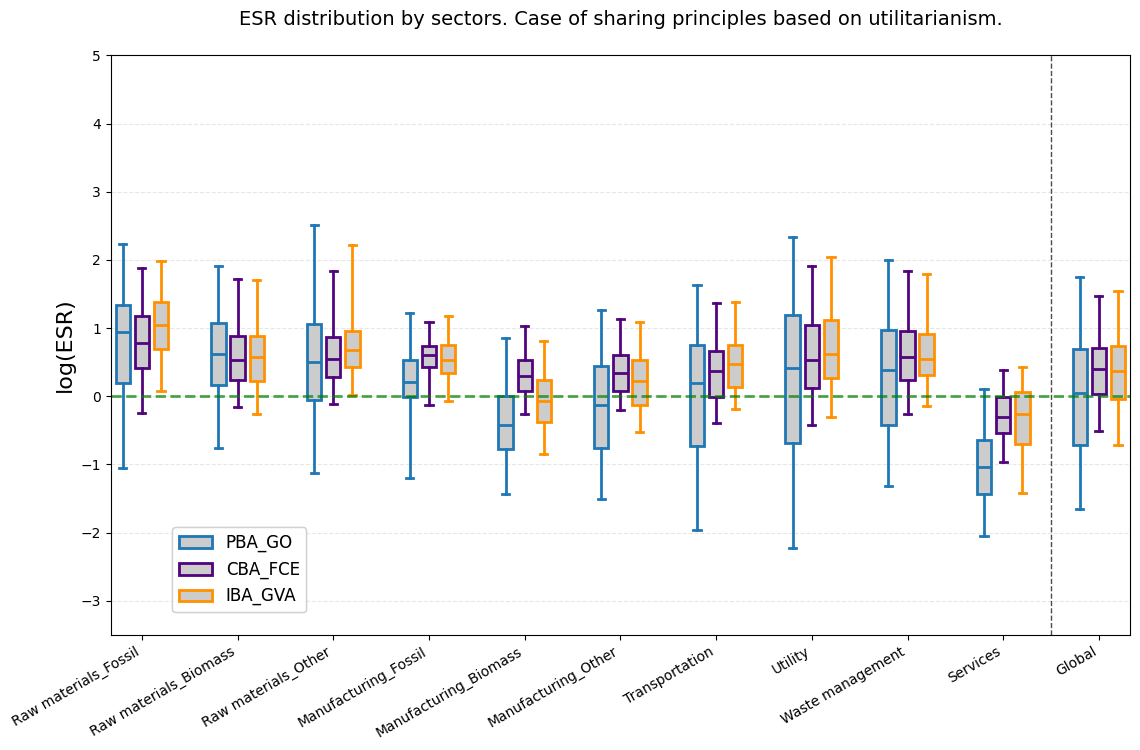

In [ ]:
# boxplot log. Utilitarianism (fig 5a) + global

df_plot = np.log10(ESR_util.copy())

df_plot = df_plot.reset_index()

data_fig5a = df_plot.copy()
data_fig5a[["ESR_PBA_GO", "ESR_CBA_FCE", "ESR_IBA_GVA"]] = data_fig5a[["ESR_PBA_GO", "ESR_CBA_FCE", "ESR_IBA_GVA"]].replace([np.inf, -np.inf], np.nan)
# data_fig5a.to_excel("data_fig5a.xlsx", index=False)

# Colonnes
sector_col = "aggregated_sectors"
region_col = "aggregated_regions"
value_vars = ["ESR_PBA_GO", "ESR_CBA_FCE", "ESR_IBA_GVA"]

sector_order = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other',
                'Manufacturing_Fossil',
                'Manufacturing_Biomass',
                'Manufacturing_Other',
                'Transportation',
                'Utility',
                'Waste management',
                'Services'
                ]

sector_order_global = sector_order + ['Global']

indicator_labels = ["PBA_GO", "CBA_FCE", "IBA_GVA"]
indicator_colors = ["#1f77b4", "#51047e", "#ff9100"]

# construire data_by_indicator en incluant 'global' (tous les secteurs réunis)
data_by_indicator = pd.DataFrame(
    {
        var: [
            (
                (s := df_plot.loc[df_plot[sector_col] == sec, var])[np.isfinite(s)] if sec != 'Global'
                else (s := df_plot[var])[np.isfinite(s)]
            )
            for sec in sector_order_global
        ]
        for var in value_vars
    },
    index=sector_order_global
)

# Positions des boxplots (3 par secteur)
base = np.arange(len(sector_order_global)) * 4
offsets = [-0.8, 0.0, 0.8]

boxplot_stats_util = {}

fig, ax = plt.subplots(figsize=(14, 8))
c = 0
y_pos = [0,0.14,0.28] * 12
for i, (var, label, color) in enumerate(zip(value_vars, indicator_labels, indicator_colors)):
    positions = base + offsets[i]
    ax.boxplot(
        data_by_indicator[var],
        positions=positions,
        widths=0.6,
        patch_artist=True,
        showfliers=False,
        boxprops=dict(facecolor="#cccccc", edgecolor=color, linewidth=2),
        medianprops=dict(color=color, linewidth=2),
        whiskerprops=dict(color=color, linewidth=2),
        capprops=dict(color=color, linewidth=2),
        whis=(5, 95)
    )

    # Calcul des statistiques (écart-type, écart interquartile) pour chaque boxplot
    for sector, pos, vals in zip(sector_order_global, positions, data_by_indicator[var]):
        if len(vals) == 0:
            continue
        std_val = np.std(vals, ddof=1)
        mean_val = np.mean(vals)
        cv_val = std_val / np.abs(mean_val) if mean_val != 0 else 0.0
        q1 = np.percentile(vals, 25)
        q3 = np.percentile(vals, 75)
        iqr = q3 - q1
        
        # Stocker les statistiques
        boxplot_stats_util[(sector, label)] = {
            'mean': mean_val,
            'std': std_val,
            'cv': cv_val,
            'q1': q1,
            'q3': q3,
            'iqr': iqr,
            'median': np.median(vals),
            'count': len(vals),
            'percentage_in_aCC': (1 - (len(vals[vals >= 0]) / len(vals))) * 100,
            'shapiro_p': stats.shapiro(vals)[1],
            'skewness': stats.skew(vals),
        }
    c += 1

boxplot_stats_df_util = pd.DataFrame(boxplot_stats_util).T
# boxplot_stats_df_util.to_excel("Stats_Figure_5a.xlsx", index=False)

# Axes
ax.set_xticks(base)
ax.set_xticklabels(sector_order_global, rotation=30, ha="right")
ax.set_xlabel("")
ax.set_yscale("linear")
ax.set_ylabel("log(ESR)", fontsize=16)
ax.set_title("ESR distribution by sectors. Case of sharing principles based on utilitarianism.\n", fontsize=14)
ax.grid(axis="y", alpha=0.3, linestyle="--")

# Fenêtre de visualisation
borne_inf = -3.5
borne_sup = 5
ax.set_ylim(borne_inf, borne_sup)

ax.axhline(y=0, color='green', linestyle='--', linewidth=2, alpha=0.7)
ax.axvline(x=38, color='black', linestyle='--', linewidth=1, alpha=0.7)

# Nombre de points affichés dans la fenêtre de visualisation
window_min, window_max = borne_inf, borne_sup
points_in_window = 0
total_points = 0
for var in value_vars:
    for vals in data_by_indicator[var]:
        total_points += len(vals)
        if len(vals) > 0:
            points_in_window += np.count_nonzero((vals >= window_min) & (vals <= window_max))

# Légende indicateurs (couleur des boxplots)
legend_handles = [Patch(facecolor="#cccccc", edgecolor=c, linewidth=2, alpha=1, label=lbl) for c, lbl in zip(indicator_colors, indicator_labels)]
leg_box = ax.legend(handles=legend_handles, title="", bbox_to_anchor=(0.2, 0.2), loc="upper right", fontsize=12, title_fontsize=15)
ax.add_artist(leg_box)

plt.tight_layout(rect=[0, 0, 0.82, 0.95])
plt.show()

c:\Users\gguillemaud\Documents\SLAM-B (new)\Papier_martin\venv_bw\Lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: divide by zero encountered in log10
  result = func(self.values, **kwargs)
c:\Users\gguillemaud\Documents\SLAM-B (new)\Papier_martin\venv_bw\Lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
c:\Users\gguillemaud\Documents\SLAM-B (new)\Papier_martin\venv_bw\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7868.
  res = hypotest_fun_out(*samples, **kwds)
c:\Users\gguillemaud\Documents\SLAM-B (new)\Papier_martin\venv_bw\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7301.
  res = hypotest_fun_out(*samples, **kwds)
c:\Users\gguillemaud\Documents\SLAM-B (

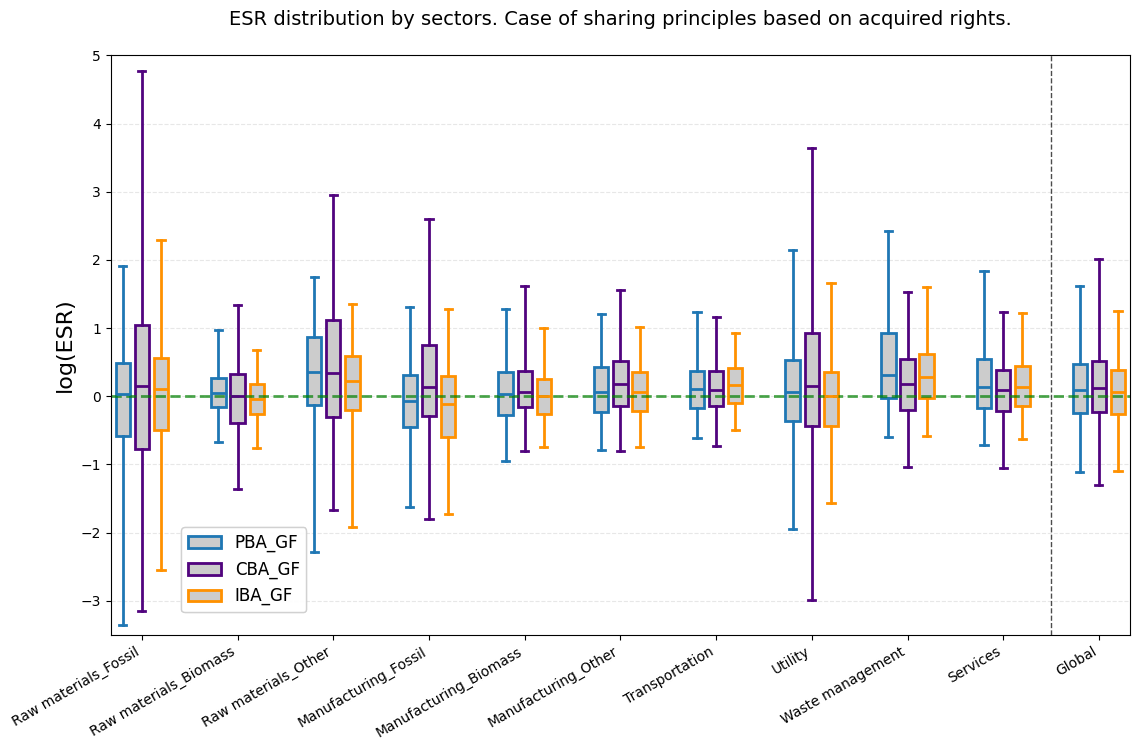

In [ ]:
# boxplot log. Grandfathering (fig 5b)

df_plot = np.log10(ESR_GF.copy())
df_plot = df_plot.reset_index()

data_fig5b = df_plot.copy()
data_fig5b[["ESR_PBA_GF", "ESR_CBA_GF", "ESR_IBA_GF"]] = data_fig5b[["ESR_PBA_GF", "ESR_CBA_GF", "ESR_IBA_GF"]].replace([np.inf, -np.inf], np.nan)
# data_fig5b.to_excel("data_fig5b.xlsx", index=False)

# Colonnes
sector_col = "aggregated_sectors"
region_col = "aggregated_regions"
value_vars = ["ESR_PBA_GF", "ESR_CBA_GF", "ESR_IBA_GF"]

sector_order = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other',
                'Manufacturing_Fossil',
                'Manufacturing_Biomass',
                'Manufacturing_Other',
                'Transportation',
                'Utility',
                'Waste management',
                'Services'
                ]

sector_order_global = sector_order + ['Global']

indicator_labels = ["PBA_GF", "CBA_GF", "IBA_GF"]
indicator_colors = ["#1f77b4", "#51047e", "#ff9100"]

data_by_indicator = pd.DataFrame(
    {
        var: [
            (
                (s := df_plot.loc[df_plot[sector_col] == sec, var])[np.isfinite(s)] if sec != 'Global'
                else (s := df_plot[var])[np.isfinite(s)]
            )
            for sec in sector_order_global
        ]
        for var in value_vars
    },
    index=sector_order_global
)

# Positions des boxplots (3 par secteur)
base = np.arange(len(sector_order_global)) * 4
offsets = [-0.8, 0.0, 0.8]

boxplot_stats_GF = {}

fig, ax = plt.subplots(figsize=(14, 8))
c = 0
y_pos = [0,0.14,0.28] * 10
for i, (var, label, color) in enumerate(zip(value_vars, indicator_labels, indicator_colors)):
    positions = base + offsets[i]
    ax.boxplot(
        data_by_indicator[var],
        positions=positions,
        widths=0.6,
        patch_artist=True,
        showfliers=False,
        boxprops=dict(facecolor="#cccccc", edgecolor=color, linewidth=2),
        medianprops=dict(color=color, linewidth=2),
        whiskerprops=dict(color=color, linewidth=2),
        capprops=dict(color=color, linewidth=2),
        whis=(5, 95)
    )

    # Calcul des statistiques (écart-type, écart interquartile) pour chaque boxplot
    for sector, pos, vals in zip(sector_order_global, positions, data_by_indicator[var]):
        if len(vals) == 0:
            continue
        std_val = np.std(vals, ddof=1)
        mean_val = np.mean(vals)
        cv_val = std_val / np.abs(mean_val) if mean_val != 0 else 0.0
        q1 = np.percentile(vals, 25)
        q3 = np.percentile(vals, 75)
        iqr = q3 - q1
        
        # Stocker les statistiques
        boxplot_stats_GF[(sector, label)] = {
            'mean': mean_val,
            'std': std_val,
            'cv': cv_val,
            'q1': q1,
            'q3': q3,
            'iqr': iqr,
            'median': np.median(vals),
            'count': len(vals),
            'percentage_in_aCC': (1 - (len(vals[vals >= 0]) / len(vals))) * 100,
            'shapiro_p': stats.shapiro(vals)[1],
            'skewness': stats.skew(vals),
        }
    c += 1

boxplot_stats_df_GF = pd.DataFrame(boxplot_stats_GF).T
# boxplot_stats_df_GF.to_excel("Stats_Figure_5b.xlsx", index=False)

# Axes
ax.set_xticks(base)
ax.set_xticklabels(sector_order_global, rotation=30, ha="right")
ax.set_xlabel("")
ax.set_yscale("linear")
ax.set_ylabel("log(ESR)", fontsize=16)
ax.set_title("ESR distribution by sectors. Case of sharing principles based on acquired rights.\n", fontsize=14)
ax.grid(axis="y", alpha=0.3, linestyle="--")

# Fenêtre de visualisation
borne_inf = -3.5
borne_sup = 5
ax.set_ylim(borne_inf, borne_sup)

ax.axhline(y=0, color='green', linestyle='--', linewidth=2, alpha=0.7)
ax.axvline(x=38, color='black', linestyle='--', linewidth=1, alpha=0.7)

# Nombre de points affichés dans la fenêtre de visualisation
window_min, window_max = borne_inf, borne_sup
points_in_window = 0
total_points = 0
for var in value_vars:
    for vals in data_by_indicator[var]:
        total_points += len(vals)
        if len(vals) > 0:
            points_in_window += np.count_nonzero((vals >= window_min) & (vals <= window_max))

# Légende indicateurs (couleur des boxplots)
legend_handles = [Patch(facecolor="#cccccc", edgecolor=c, linewidth=2, alpha=1, label=lbl) for c, lbl in zip(indicator_colors, indicator_labels)]
leg_box = ax.legend(handles=legend_handles, title="", bbox_to_anchor=(0.2, 0.2), loc="upper right", fontsize=12, title_fontsize=15)
ax.add_artist(leg_box)

plt.tight_layout(rect=[0, 0, 0.82, 0.95])
plt.show()

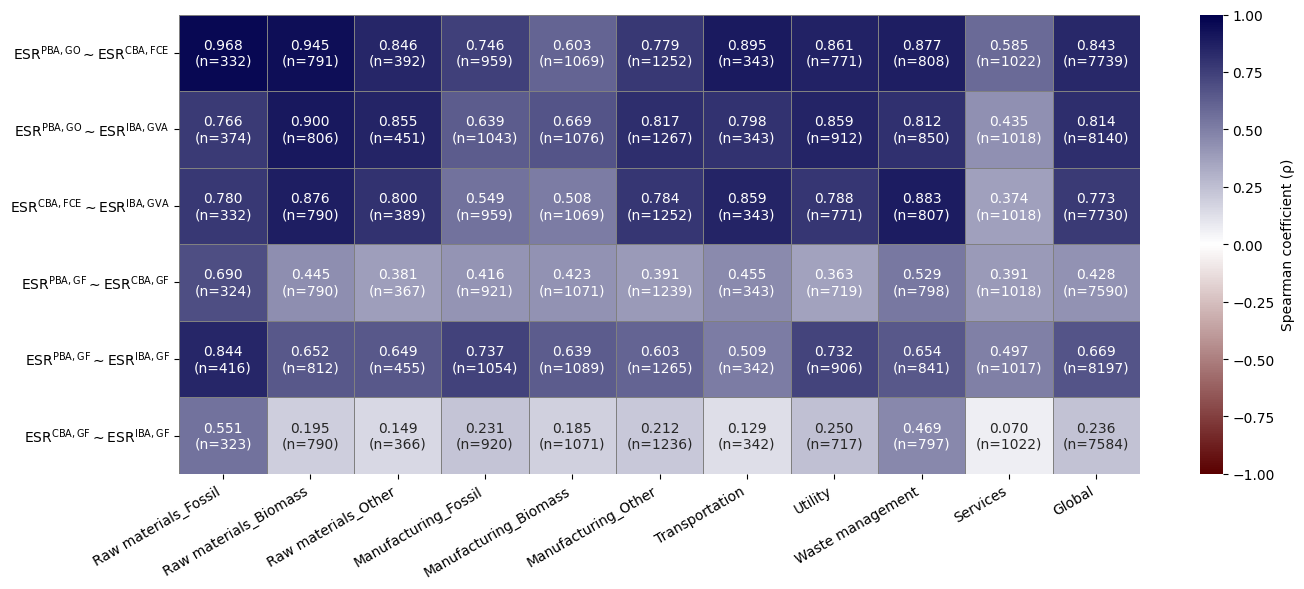

In [13]:
# Heatmap Spearman coefficient (fig 6)

esr_df = ESR_util.copy().assign(
    ESR_PBA_GF=ESR_GF['ESR_PBA_GF'],
    ESR_CBA_GF=ESR_GF['ESR_CBA_GF'],
    ESR_IBA_GF=ESR_GF['ESR_IBA_GF'],
)

esr_df['aggregated_sectors'] = esr_df.index.get_level_values(3)

sector_order = [
    'Raw materials_Fossil',
    'Raw materials_Biomass',
    'Raw materials_Other',
    'Manufacturing_Fossil',
    'Manufacturing_Biomass',
    'Manufacturing_Other',
    'Transportation',
    'Utility',
    'Waste management',
    'Services',
]
sector_order_global = sector_order + ['Global']

comparison = [("ESR_PBA_GO", "ESR_CBA_FCE"), ("ESR_PBA_GO", "ESR_IBA_GVA"), ("ESR_CBA_FCE", "ESR_IBA_GVA"), ("ESR_PBA_GF", "ESR_CBA_GF"), ("ESR_PBA_GF", "ESR_IBA_GF"), ("ESR_CBA_GF", "ESR_IBA_GF")]
comparison_labels = [
    r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{CBA,FCE}}$',
    r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$',
    r'$\mathrm{ESR}^{\mathrm{CBA,FCE}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$',
    r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{CBA,GF}}$',
    r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$',
    r'$\mathrm{ESR}^{\mathrm{CBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$',
]

index = pd.MultiIndex.from_product([comparison, sector_order_global], names=['comparison', 'sector'])

Regr_results = pd.DataFrame(
    {
        'count': 0,
        'spearman': np.nan,
        'p-value': np.nan
    },
    index=index
)

for (line, sector) in index:
    if sector == 'Global':
        subset_data = esr_df
    else:
        mask_subset = (esr_df['aggregated_sectors'] == sector)
        subset_data = esr_df[mask_subset]

    mask_comp = np.logical_not(np.isnan(subset_data[line[0]])) & np.logical_not(np.isnan(subset_data[line[1]]))
    n_count = mask_comp.sum()
    Regr_results.loc[(line, sector), 'count'] = n_count

    if n_count > 1:
        x_1 = subset_data[line[0]][mask_comp].values
        y_2 = subset_data[line[1]][mask_comp].values
        rho, p_value = stats.spearmanr(x_1, y_2, nan_policy='omit')
        Regr_results.loc[(line, sector), 'spearman'] = rho
        Regr_results.loc[(line, sector), 'p-value'] = p_value
    else:
        Regr_results.loc[(line, sector), 'spearman'] = np.nan
        Regr_results.loc[(line, sector), 'p-value'] = np.nan

data_fig6 = Regr_results.copy().reset_index()
# data_fig6.to_excel("data_fig6.xlsx")

spearman_pivot = Regr_results['spearman'].unstack(fill_value=np.nan)
count_pivot = Regr_results['count'].unstack(fill_value=0).astype(int)

spearman_pivot = spearman_pivot.reindex(index=comparison, columns=sector_order_global)
count_pivot = count_pivot.reindex(index=comparison, columns=sector_order_global)

annotations = np.empty_like(spearman_pivot, dtype=object)
for i in range(spearman_pivot.shape[0]):
    for j in range(spearman_pivot.shape[1]):
        rho_val = spearman_pivot.iloc[i, j]
        count_val = count_pivot.iloc[i, j]
        if np.isnan(rho_val):
            annotations[i, j] = ''
        else:
            annotations[i, j] = f"{rho_val:.3f}\n(n={count_val})"

# Palette divergente avec blanc à 0: rouge foncé -> blanc -> bleu foncé
cmap_focus = mcolors.LinearSegmentedColormap.from_list(
    "dark_red_white_blue",
    [(0.0, "#5a0000"), (0.5, "#ffffff"), (1.0, "#00004d")],
)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    spearman_pivot,
    annot=annotations,
    fmt='',
    cmap=cmap_focus,
    ax=ax,
    cbar_kws={'label': 'Spearman coefficient (ρ)'},
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor='gray'
)

ax.set_xticklabels(sector_order_global, rotation=30, ha="right")
ax.set_yticklabels(comparison_labels, rotation=0)
#ax.set_title('Heatmap coefficient de Spearman (désagrégé, n_tot~9800)\n', fontsize=13, fontweight='bold')
ax.set_xlabel('', fontsize=11, fontweight='bold')
ax.set_ylabel('', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()